In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Load the processed feature matrix
X_processed = pd.read_csv(
    "../data/processed/customer_features.csv"
)

# Load customer metadata separately
metadata = pd.read_csv(
    "../data/processed/customer_metadata.csv"
)

print("Feature matrix shape:", X_processed.shape)
print("Metadata shape:", metadata.shape)

X_processed.head()


Feature matrix shape: (7043, 45)
Metadata shape: (7043, 2)


,num__SeniorCitizen,num__tenure,num__MonthlyCharges,num__TotalCharges,cat__gender_Female,cat__gender_Male,cat__Partner_No,cat__Partner_Yes,cat__Dependents_No,cat__Dependents_Yes,...,cat__StreamingMovies_Yes,cat__Contract_Month-to-month,cat__Contract_One year,cat__Contract_Two year,cat__PaperlessBilling_No,cat__PaperlessBilling_Yes,cat__PaymentMethod_Bank transfer (automatic),cat__PaymentMethod_Credit card (automatic),cat__PaymentMethod_Electronic check,cat__PaymentMethod_Mailed check
0,-0.439916,-1.277445,-1.160323,-0.992611,1.0,0.0,0.0,1.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,-0.439916,0.066327,-0.259629,-0.172165,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,-0.439916,-1.236724,-0.362660,-0.958066,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,-0.439916,0.514251,-0.746535,-0.193672,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,-0.439916,-1.236724,0.197365,-0.938874,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [2]:

# Test different numbers of clusters
k_values = range(2, 11)

inertia_values = []
silhouette_values = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = model.fit_predict(X_processed)

    inertia_values.append(model.inertia_)
    silhouette_values.append(
        silhouette_score(
            X_processed,
            cluster_labels,
            sample_size=2000,
            random_state=42
        )
    )

print("K-Means evaluation completed.")

for k, inertia, silhouette in zip(
    k_values, inertia_values, silhouette_values
):
    print(
        f"K={k}: Inertia={inertia:.2f}, "
        f"Silhouette={silhouette:.4f}"
    )


K-Means evaluation completed.
K=2: Inertia=68648.35, Silhouette=0.2353
K=3: Inertia=55586.85, Silhouette=0.2383
K=4: Inertia=50813.27, Silhouette=0.2305
K=5: Inertia=47871.27, Silhouette=0.1960
K=6: Inertia=45698.66, Silhouette=0.1856
K=7: Inertia=43809.60, Silhouette=0.1890
K=8: Inertia=42031.39, Silhouette=0.1555
K=9: Inertia=40929.55, Silhouette=0.1408
K=10: Inertia=39895.00, Silhouette=0.1398


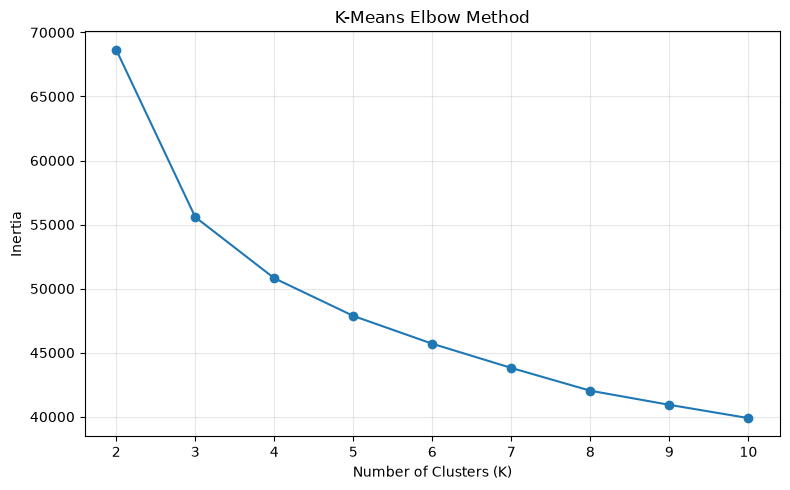

In [3]:

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker="o")
plt.title("K-Means Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


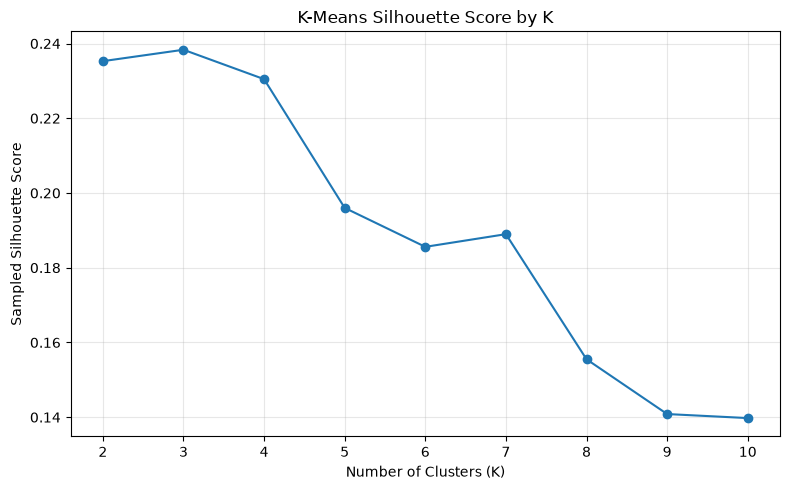

In [4]:

plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_values, marker="o")
plt.title("K-Means Silhouette Score by K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Sampled Silhouette Score")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [5]:

# Fit the initial K-Means model
kmeans_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_model.fit_predict(X_processed)

# Attach cluster assignments to the separate metadata
cluster_results = metadata.copy()
cluster_results["Cluster"] = cluster_labels

# Inspect cluster sizes
print("Cluster sizes:")
print(
    cluster_results["Cluster"]
    .value_counts()
    .sort_index()
)

# Calculate the observed churn rate within each cluster
print("\nObserved churn rate by cluster (%):")
print(
    cluster_results.groupby("Cluster")["Churn"]
    .apply(lambda values: (values == "Yes").mean() * 100)
    .round(2)
)

# Inspect churn counts by cluster
print("\nChurn counts by cluster:")
print(
    pd.crosstab(
        cluster_results["Cluster"],
        cluster_results["Churn"]
    )
)


Cluster sizes:
Cluster
0    1526
1    3189
2    2328
Name: count, dtype: int64

Observed churn rate by cluster (%):
Cluster
0     7.40
1    44.03
2    15.12
Name: Churn, dtype: float64

Churn counts by cluster:
Churn      No   Yes
Cluster            
0        1413   113
1        1785  1404
2        1976   352


In [6]:

# Combine original customer features with cluster assignments
customer_profile = pd.read_csv(
    "../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

customer_profile["Cluster"] = cluster_labels

# Convert TotalCharges to numeric for profiling
customer_profile["TotalCharges"] = pd.to_numeric(
    customer_profile["TotalCharges"],
    errors="coerce"
).fillna(0)

# Compare numerical characteristics across clusters
numerical_profile = (
    customer_profile.groupby("Cluster")[
        ["tenure", "MonthlyCharges", "TotalCharges"]
    ]
    .mean()
    .round(2)
)

print("Average customer characteristics by cluster:")
print(numerical_profile)


Average customer characteristics by cluster:
         tenure  MonthlyCharges  TotalCharges
Cluster                                      
0         30.55           21.08        662.60
1         15.30           67.86       1018.08
2         56.95           89.15       5068.03


In [7]:

# Compare contract type across the three clusters
contract_distribution = pd.crosstab(
    customer_profile["Cluster"],
    customer_profile["Contract"],
    normalize="index"
) * 100

print("Contract type distribution within each cluster (%):")
print(contract_distribution.round(2))

# Compare internet service across the clusters
internet_distribution = pd.crosstab(
    customer_profile["Cluster"],
    customer_profile["InternetService"],
    normalize="index"
) * 100

print("\nInternet service distribution within each cluster (%):")
print(internet_distribution.round(2))

# Compare payment methods across the clusters
payment_distribution = pd.crosstab(
    customer_profile["Cluster"],
    customer_profile["PaymentMethod"],
    normalize="index"
) * 100

print("\nPayment method distribution within each cluster (%):")
print(payment_distribution.round(2))


Contract type distribution within each cluster (%):
Contract  Month-to-month  One year  Two year
Cluster                                     
0                  34.34     23.85     41.81
1                  87.02     10.50      2.48
2                  24.74     33.25     42.01

Internet service distribution within each cluster (%):
InternetService    DSL  Fiber optic     No
Cluster                                   
0                 0.00         0.00  100.0
1                47.66        52.34    0.0
2                38.70        61.30    0.0

Payment method distribution within each cluster (%):
PaymentMethod  Bank transfer (automatic)  Credit card (automatic)  \
Cluster                                                             
0                                  21.76                    21.69   
1                                  14.46                    14.77   
2                                  32.26                    30.93   

PaymentMethod  Electronic check  Mailed check  
Clus

In [8]:

# Calculate the overall observed churn rate
overall_churn_rate = (
    (customer_profile["Churn"] == "Yes").mean() * 100
)

# Calculate each cluster's observed churn rate
cluster_churn_rates = (
    customer_profile.groupby("Cluster")["Churn"]
    .apply(lambda values: (values == "Yes").mean() * 100)
)

print(f"Overall churn rate: {overall_churn_rate:.2f}%")
print("\nCluster churn rate compared with overall:")
for cluster, rate in cluster_churn_rates.items():
    difference = rate - overall_churn_rate
    print(
        f"Cluster {cluster}: {rate:.2f}% "
        f"({difference:+.2f} percentage points vs overall)"
    )


Overall churn rate: 26.54%

Cluster churn rate compared with overall:
Cluster 0: 7.40% (-19.13 percentage points vs overall)
Cluster 1: 44.03% (+17.49 percentage points vs overall)
Cluster 2: 15.12% (-11.42 percentage points vs overall)


## K-Means Clustering — Summary

### Objective
Applied K-Means clustering to segment telecom customers based on their numerical and categorical characteristics.

### Methodology
- Loaded the cleaned, scaled, and one-hot-encoded customer features.
- Evaluated values of K from 2 to 10 using inertia and sampled silhouette scores.
- Selected K = 3 as the initial candidate because it achieved the highest sampled silhouette score among the tested values.
- Examined cluster sizes, customer characteristics, contract types, internet services, payment methods, and observed churn rates.

### Results

| Cluster | Customers | Average Tenure (months) | Average Monthly Charges | Observed Churn Rate |
|---|---:|---:|---:|---:|
| 0 | 1,526 | 30.55 | 21.08 | 7.40% |
| 1 | 3,189 | 15.30 | 67.86 | 44.03% |
| 2 | 2,328 | 56.95 | 89.15 | 15.12% |

- **Cluster 0:** Lower monthly charges, no internet service, and lower observed churn.
- **Cluster 1:** Shorter tenure, predominantly month-to-month contracts, frequent electronic-check usage, and the highest observed churn.
- **Cluster 2:** Longer tenure, higher monthly charges, and lower observed churn than the overall dataset.

### Evaluation
The highest sampled silhouette score was 0.2383 at K = 3. This indicates relatively weak cluster separation, so the segments should be treated as provisional rather than naturally distinct customer groups.

### Business Implications
Cluster 1 is a promising segment for further investigation into retention strategies. Contract type, tenure, payment method, and service characteristics may help guide subsequent analysis.

### Limitations
- Cluster selection was based on a limited range of K values and sampled silhouette scores.
- Differences in churn rates are descriptive associations, not evidence of causation.
- The final algorithm should be selected after comparing K-Means with hierarchical clustering and DBSCAN.

### Conclusion
K-Means produced three interpretable customer segments with different observed churn rates. These findings establish a baseline for comparing clustering algorithms and evaluating the usefulness of the resulting segments.